# 03 — Model evaluation

**Research question:** how accurate are our pre-match predictions compared with actual match results?

This notebook answers it with a **walk-forward backtest**: we pretend to use each model live from
the start of 2019/20 until today. Before every matchday, every model is retrained on all matches played
*before* that day, then predicts that day's matches. No prediction ever sees its own result or anything later.

We then measure the predictions with three scoring rules (lower = better for all three):

| Score | What it measures | Always 1/3 scores |
|---|---|---|
| **Log loss** | −log(probability given to what happened). Punishes confident mistakes hard. | 1.099 |
| **Brier score** | Squared distance between the probabilities and what happened. | 0.667 |
| **RPS** | Like Brier, but respects the order home win → draw → away win: predicting a draw when the home team won is "less wrong" than predicting an away win. The standard score for football. | ≈ 0.24 (depends on the draw share) |

Plus **calibration**: when the model says 40%, does it happen about 40% of the time?

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import PROCESSED_DIR, load_processed
from src.evaluation import (CLASSES, calibration_table, paired_difference, probs_of, rps,
                            score_table, walk_forward_backtest)
from src.models import fit_baseline_before, fit_logistic_before, fit_poisson_before

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
COLORS = {"Baseline": "#a0aec0", "Logistic": "#2b6cb0", "Poisson": "#c05621",
          "Logistic (xG only)": "#38a169", "Logistic (results only)": "#805ad5"}

## 0. Run the tests first

In [2]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

...............................................................          [100%]
63 passed in 3.36s



## 1. The models in the backtest

The three Stage 2 models, plus two **feature-group variants** of the logistic model. They answer the
"especially xG" part of the project: does knowing a team's recent xG help more than knowing its recent results?

| Model | Inputs |
|---|---|
| Baseline | nothing about the teams; historical share of H/D/A |
| Logistic | all 8 form differences |
| Poisson | all 16 home and away form features → expected goals → H/D/A |
| Logistic (xG only) | xG created, xG conceded, venue xG difference |
| Logistic (results only) | goals scored, goals conceded, points, win rate, venue points per game |

In [3]:
XG_ONLY = ["xg_for_diff", "xg_against_diff", "venue_xgd_diff"]
RESULTS_ONLY = ["goals_for_diff", "goals_against_diff", "points_diff", "win_rate_diff", "venue_ppg_diff"]

FITTERS = {
    "Baseline": fit_baseline_before,
    "Logistic": fit_logistic_before,
    "Poisson": fit_poisson_before,
    "Logistic (xG only)": lambda m, d: fit_logistic_before(m, d, features=XG_ONLY),
    "Logistic (results only)": lambda m, d: fit_logistic_before(m, d, features=RESULTS_ONLY),
}
MAIN = ["Baseline", "Logistic", "Poisson"]

## 2. Run the walk-forward backtest

Backtest window: **1 July 2019 to today** (2019/20 to the 2026/27 matches played so far). The first
prediction is trained on three seasons (2016/17–2018/19), and the training set grows every matchday.
This takes about half a minute.

Note: the regularisation strengths were chosen in notebook 02 using 2024/25, which is inside this
window. The log-loss curves there were flat, so the effect on these results is negligible.

In [4]:
features = load_processed()
BACKTEST_START = "2019-07-01"

backtest = walk_forward_backtest(features, FITTERS, BACKTEST_START)
path = PROCESSED_DIR / "backtest_predictions.csv"
backtest.to_csv(path, index=False)
print(f"Saved {len(backtest)} rows to {path.relative_to(PROJECT_ROOT)}")
backtest.head()

  100/843 matchdays done


  200/843 matchdays done


  300/843 matchdays done


  400/843 matchdays done


  500/843 matchdays done


...

  700/843 matchdays done


  800/843 matchdays done


Backtest done: 2666 matches on 843 matchdays, 5 models.


Saved 13330 rows to data/processed/backtest_predictions.csv


,date,season,home_team,away_team,home_goals,away_goals,result,model,p_H,p_D,p_A,n_train
0,2019-08-10 12:30:00,1920,West Ham,Manchester City,0,5,A,Baseline,0.475022,0.222612,0.302366,1141
1,2019-08-10 15:00:00,1920,Burnley,Southampton,3,0,H,Baseline,0.475022,0.222612,0.302366,1141
2,2019-08-10 15:00:00,1920,Crystal Palace,Everton,0,0,D,Baseline,0.475022,0.222612,0.302366,1141
3,2019-08-10 15:00:00,1920,Watford,Brighton,0,3,A,Baseline,0.475022,0.222612,0.302366,1141
4,2019-08-10 12:30:00,1920,West Ham,Manchester City,0,5,A,Logistic,0.280054,0.225798,0.494147,1044


## 3. Overall scores

Every model is scored on exactly the same matches.

In [5]:
results, _ = probs_of(backtest, "Baseline")
predictions = {name: probs_of(backtest, name)[1] for name in FITTERS}

uniform = np.full((len(results), 3), 1 / 3)
scores = score_table(results, {"Uniform 1/3": uniform, **predictions})
print(f"{len(results)} matches, {backtest['date'].min().date()} to {backtest['date'].max().date()}")
scores.round(4)

2666 matches, 2019-08-10 to 2026-10-11


,log loss,Brier,RPS,accuracy
Uniform 1/3,1.0986,0.6667,0.2381,0.4332
Baseline,1.0713,0.6487,0.2335,0.4332
Logistic,1.0061,0.6002,0.2097,0.5131
Poisson,1.0047,0.6000,0.2097,0.5150
Logistic (xG only),1.0049,0.5994,0.2094,0.5135
Logistic (results only),1.0232,0.6135,0.2160,0.4996


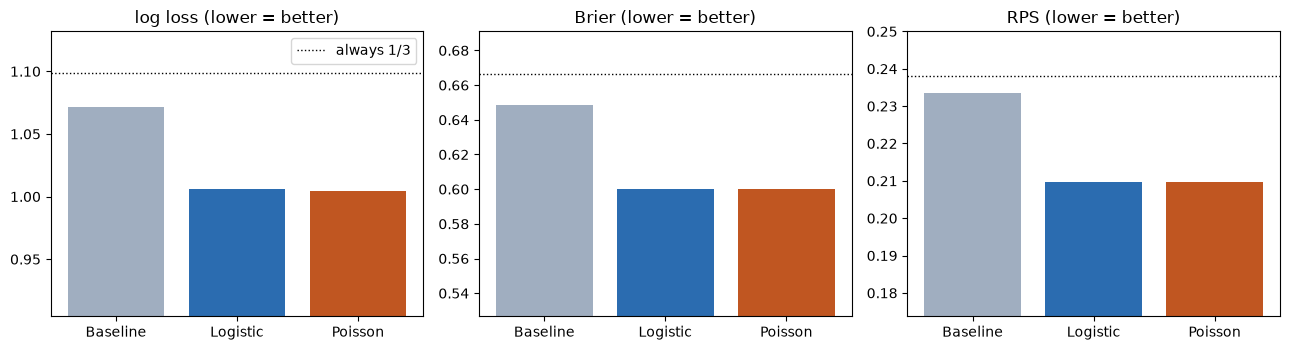

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric in zip(axes, ["log loss", "Brier", "RPS"]):
    vals = scores.loc[MAIN, metric]
    ax.bar(vals.index, vals.values, color=[COLORS[m] for m in vals.index])
    ax.axhline(scores.loc["Uniform 1/3", metric], color="black", ls=":", lw=1, label="always 1/3")
    pad = (vals.max() - vals.min()) * 1.5
    ax.set_ylim(vals.min() - pad, scores.loc["Uniform 1/3", metric] + pad / 3)
    ax.set_title(f"{metric} (lower = better)")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4. Are the differences real or luck?

Each model is compared with another **on the same matches** (a paired comparison), which removes
match-to-match difficulty. The table shows the average per-match difference with a 95% interval.
**Negative = the first model is better.** If the interval includes 0, the data cannot separate the two.

In [7]:
pairs = [
    ("Logistic", "Baseline"),
    ("Poisson", "Baseline"),
    ("Logistic", "Poisson"),
    ("Logistic (xG only)", "Logistic (results only)"),
    ("Logistic", "Logistic (xG only)"),
]
rows = []
for a, b in pairs:
    for metric in ["RPS", "log loss"]:
        d = paired_difference(results, predictions[a], predictions[b], metric)
        rows.append({"comparison": f"{a}  vs  {b}", "metric": metric, **d,
                     "clear winner?": "yes" if d["ci high"] < 0 or d["ci low"] > 0 else "no"})
comparisons = pd.DataFrame(rows).set_index(["comparison", "metric"]).drop(columns="n")
comparisons.round(4)

mean diff  ci low  ci high clear winner?
comparison                                      metric                                            
Logistic  vs  Baseline                          RPS         -0.0239 -0.0288  -0.0189           yes
                                                log loss    -0.0652 -0.0800  -0.0505           yes
Poisson  vs  Baseline                           RPS         -0.0239 -0.0288  -0.0189           yes
                                                log loss    -0.0666 -0.0811  -0.0522           yes
Logistic  vs  Poisson                           RPS          0.0000 -0.0008   0.0008            no
                                                log loss     0.0014 -0.0018   0.0046            no
Logistic (xG only)  vs  Logistic (results only) RPS         -0.0066 -0.0098  -0.0034           yes
                                                log loss    -0.0183 -0.0278  -0.0087           yes
Logistic  vs  Logistic (xG only)                RPS          0.0003 -0.0006   0.0011            no
                                                log loss     0.0011 -0.0016   0.0039            no

## 5. Scores per season

Does the advantage hold every season, or is it driven by one lucky year? 2026/27 is only partly played,
so its score is noisy.

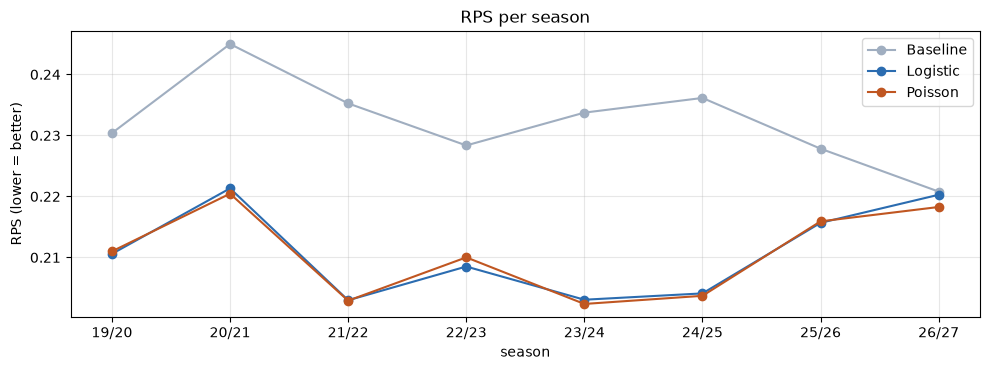

model,matches,Baseline,Logistic,Poisson,Logistic (xG only),Logistic (results only)
season,,,,,,
1920,362,0.2304,0.2106,0.2110,0.2114,0.2116
2021,374,0.2450,0.2213,0.2204,0.2206,0.2289
2122,374,0.2353,0.2030,0.2029,0.2012,0.2117
2223,374,0.2284,0.2085,0.2100,0.2070,0.2169
2324,374,0.2337,0.2031,0.2024,0.2047,0.2059
2425,374,0.2361,0.2041,0.2037,0.2025,0.2175
2526,380,0.2278,0.2157,0.2159,0.2167,0.2188
2627,54,0.2208,0.2203,0.2183,0.2222,0.2186


In [8]:
per_season = (backtest.groupby(["season", "model"])
              .apply(lambda g: rps(g["result"], g[["p_H", "p_D", "p_A"]].to_numpy()), include_groups=False)
              .unstack()[list(FITTERS)])
per_season.insert(0, "matches", backtest[backtest["model"] == "Baseline"].groupby("season").size())

fig, ax = plt.subplots(figsize=(10, 3.8))
labels = [f"{str(s)[:2]}/{str(s)[2:]}" for s in per_season.index]
for name in MAIN:
    ax.plot(labels, per_season[name], marker="o", color=COLORS[name], label=name)
ax.set_ylabel("RPS (lower = better)")
ax.set_xlabel("season")
ax.set_title("RPS per season")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
per_season.round(4)

**2020/21** was played almost entirely without crowds (COVID-19). Home advantage nearly disappeared that
season, so the baseline, which leans heavily on "home teams win 45%", had its worst year.

In [9]:
home_share = features.groupby("season")["result"].apply(lambda r: (r == "H").mean())
print("Share of home wins per season:")
print(home_share.round(3).to_string())

Share of home wins per season:
season
1617    0.492
1718    0.455
1819    0.476
1920    0.453
2021    0.379
2122    0.429
2223    0.484
2324    0.461
2425    0.408
2526    0.426
2627    0.383


## 6. Calibration

For each outcome, matches are grouped by the predicted probability (0–10%, 10–20%, ...). In each group we
compare the **average prediction** with **how often it actually happened**. A well-calibrated model sits on
the diagonal. Point size shows how many matches are in the group. Groups with fewer than 20 matches are
left out of the plot because one or two results would swing them wildly; the tables below show every group.

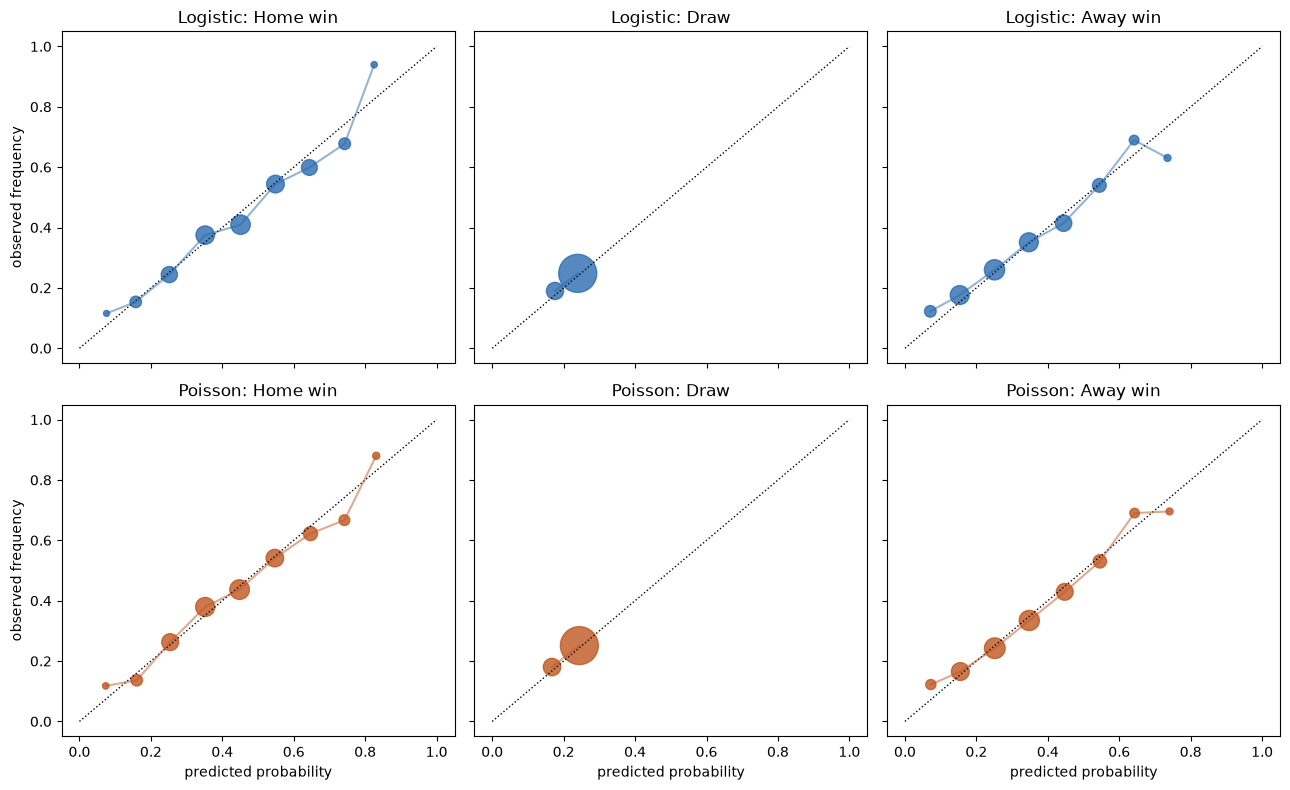

In [10]:
MIN_BIN = 20
fig, axes = plt.subplots(len(MAIN) - 1, 3, figsize=(13, 8), sharex=True, sharey=True)
for r, name in enumerate(["Logistic", "Poisson"]):
    for c, (outcome, label) in enumerate(zip(CLASSES, ["Home win", "Draw", "Away win"])):
        ax = axes[r, c]
        table = calibration_table(results, predictions[name], outcome)
        table = table[table["matches"] >= MIN_BIN]
        ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1)
        ax.scatter(table["predicted"], table["observed"], s=table["matches"] / 3 + 10,
                   color=COLORS[name], alpha=0.8)
        ax.plot(table["predicted"], table["observed"], color=COLORS[name], alpha=0.5)
        ax.set_title(f"{name}: {label}")
        if r == 1:
            ax.set_xlabel("predicted probability")
        if c == 0:
            ax.set_ylabel("observed frequency")
plt.tight_layout()
plt.show()

In [11]:
for name in ["Logistic", "Poisson"]:
    print(f"\n{name}, home win:")
    print(calibration_table(results, predictions[name], "H").round(3).to_string())


Logistic, home win:
         predicted  observed  matches
0.0-0.1      0.076     0.115       26
0.1-0.2      0.157     0.153      176
0.2-0.3      0.252     0.244      377
0.3-0.4      0.352     0.375      499
0.4-0.5      0.451     0.409      557
0.5-0.6      0.549     0.544      456
0.6-0.7      0.644     0.599      359
0.7-0.8      0.743     0.678      183
0.8-0.9      0.825     0.939       33

Poisson, home win:
         predicted  observed  matches
0.0-0.1      0.073     0.118       34
0.1-0.2      0.160     0.136      176
0.2-0.3      0.254     0.263      415
0.3-0.4      0.352     0.379      538
0.4-0.5      0.448     0.437      570
0.5-0.6      0.547     0.541      451
0.6-0.7      0.647     0.622      278
0.7-0.8      0.742     0.667      150
0.8-0.9      0.831     0.880       50
0.9-1.0      0.926     1.000        4


### Draws

Football models often under-predict draws, so check: average predicted draw probability vs the actual share.
Note that draw predictions sit in a narrow range (mostly 20–30%). The models struggle to tell which
matches will be draws, which is typical for football and the main reason accuracy stays around 50%.

In [12]:
draw_check = pd.DataFrame({
    "avg predicted P(draw)": {n: p[:, 1].mean() for n, p in predictions.items() if n in MAIN},
    "lowest P(draw)": {n: p[:, 1].min() for n, p in predictions.items() if n in MAIN},
    "highest P(draw)": {n: p[:, 1].max() for n, p in predictions.items() if n in MAIN},
})
print(f"Actual draw share: {(results == 'D').mean():.3f}")
draw_check.round(3)

Actual draw share: 0.238


,avg predicted P(draw),lowest P(draw),highest P(draw)
Baseline,0.228,0.223,0.234
Logistic,0.229,0.090,0.339
Poisson,0.230,0.052,0.294


## 7. Confident predictions

When a model is very sure (top favourite ≥ 60%), how often is it right? This is calibration in plain words.

In [13]:
rows = []
for name in ["Logistic", "Poisson"]:
    p = predictions[name]
    top = p.max(axis=1)
    hit = (p.argmax(axis=1) == results.map(CLASSES.index).to_numpy())
    for lo, hi in [(0.33, 0.45), (0.45, 0.6), (0.6, 0.75), (0.75, 1.0)]:
        mask = (top >= lo) & (top < hi)
        rows.append({"model": name, "favourite's probability": f"{lo:.0%}–{hi:.0%}",
                     "matches": int(mask.sum()), "avg predicted": top[mask].mean(),
                     "favourite won": hit[mask].mean()})
pd.DataFrame(rows).set_index(["model", "favourite's probability"]).round(3)

matches  avg predicted  favourite won
model    favourite's probability                                       
Logistic 33%–45%                      767          0.412          0.382
         45%–60%                     1157          0.520          0.512
         60%–75%                      624          0.662          0.622
         75%–100%                     118          0.791          0.805
Poisson  33%–45%                      856          0.409          0.411
         45%–60%                     1155          0.518          0.502
         60%–75%                      510          0.663          0.641
         75%–100%                     145          0.804          0.786

## 8. Summary

The cell below prints the main numbers for the report.

In [14]:
lp = comparisons.loc[("Logistic  vs  Poisson", "RPS")]
xr = comparisons.loc[("Logistic (xG only)  vs  Logistic (results only)", "RPS")]
print(f"Backtest: {len(results)} Premier League matches, {backtest['date'].min().date()} to {backtest['date'].max().date()}")
print()
for name in MAIN:
    s = scores.loc[name]
    print(f"{name:<9} log loss {s['log loss']:.4f}  Brier {s['Brier']:.4f}  RPS {s['RPS']:.4f}  accuracy {s['accuracy']:.1%}")
print()
print(f"Logistic vs Poisson RPS difference: {lp['mean diff']:+.4f} "
      f"(95% interval {lp['ci low']:+.4f} to {lp['ci high']:+.4f}) -> clear winner: {lp['clear winner?']}")
print(f"xG-only vs results-only RPS difference: {xr['mean diff']:+.4f} "
      f"(95% interval {xr['ci low']:+.4f} to {xr['ci high']:+.4f}) -> clear winner: {xr['clear winner?']}")

Backtest: 2666 Premier League matches, 2019-08-10 to 2026-10-11

Baseline  log loss 1.0713  Brier 0.6487  RPS 0.2335  accuracy 43.3%
Logistic  log loss 1.0061  Brier 0.6002  RPS 0.2097  accuracy 51.3%
Poisson   log loss 1.0047  Brier 0.6000  RPS 0.2097  accuracy 51.5%

Logistic vs Poisson RPS difference: +0.0000 (95% interval -0.0008 to +0.0008) -> clear winner: no
xG-only vs results-only RPS difference: -0.0066 (95% interval -0.0098 to -0.0034) -> clear winner: yes


### Findings

*Written from the backtest above. If you re-run with newer data, check the numbers still say the same.*

1. **Both models clearly beat the baseline** on all three scores, and the 95% intervals are far from 0.
   Knowing the teams' recent form is genuinely useful.
2. **Logistic and Poisson are tied.** Their difference is far smaller than the uncertainty. They use
   the same information, and the different model structure makes no practical difference.
3. **xG beats results.** A model using only xG features clearly beats one using only goals, points and
   wins, and adding the results features to xG adds nothing. Recent xG is a better guide to a team's
   strength than its recent results, because results contain more luck. This supports the project's focus on xG.
4. **Calibration is good.** When a model says 50% the outcome happens about 50% of the time. The biggest
   home favourites (70–80%) win slightly less often than predicted, so the models are a little overconfident there.
5. **Draws are the weak spot.** The average draw probability matches the real draw share, but the models
   can barely tell *which* matches will be draws. Almost every prediction is 20–30% draw. This
   is the main reason accuracy stays around 50%.
6. **Improvement is real but modest.** Football is very random. Even a good model only lowers RPS from
   about 0.23 to 0.21. Bookmaker odds are the usual benchmark for "how good can it get"; we have no odds
   data, so comparing against them would be a natural next step.
7. **2020/21 (no crowds)** had far fewer home wins, which hurt the baseline most. The form-based models
   adapted better because they look at recent matches.

**Limitations:** one league; matches are treated as independent in the intervals; features ignore
injuries, transfers, managers and line-ups; teams new to the data have no predictions for their first 5 matches;
regularisation was chosen on 2024/25, which is inside the backtest window (minor effect).